In [1]:
import find as fnd
import configs as cfg
import createconfig as cc
import photplotlib as pplib
import check as chk
from importlib import reload
reload(fnd)
reload(cfg)
reload(cc)
reload(pplib)
reload(chk)
from photplotlib import PhotometryPipeline, LightCurvePlotter

[harvard_mirrors] SIMBAD -> simbad.harvard.edu | VizieR -> vizier.cfa.harvard.edu
The current archive release 3.15 contains two breaking changes. Please see https://www.cosmos.esa.int/web/gaia/news#GACSrelease315 for details. In case of questions or feedback, please consult the Gaia helpdesk at https://www.cosmos.esa.int/web/gaia/gaia-helpdesk.


In [16]:
# Set the directory containing the image folders and the filt
core = '/Users/nhaurber/Data/PCEB/DECVn g 2026-03-25/' # parent directory where images are and light curves will be saved
LK_PATH = core #+ 'lightcurves/' # path where light curves should save inside parent directory
images_location = core #+ 'Gaia1238/'
observer = 'NH' # initials; they will be saved in file names
DATE = '2026-03-25' # date of observation

#config_file = core + 'Gaia1238/Gaia_1238_config.ini' # path to config file for target inside parent directory

# plot phased? show comparison stars?
phased = False
comps = True

# Set the gain and read noise
RDNOISE = 1.7
GAIN = 1.76

# Set the starting aperture and annulus radii
AP_R = 15
AN_I = 25
AN_O = 30

non_sid = False

winer_loc = {'lon': -110-36/60-6.42/3600, 'lat': 31+39/60+56.08/3600, 'elevation': 1515.7}

In [17]:
# ---- USER INPUTS FOR PHOTOMETRY ----
TARGET = "DE CVn"
PERIOD = 0
IS_PHASE = False
PHASE_ZERO = 0
REF_IMAGE_NAME = '/Users/nhaurber/Data/PCEB/DECVn g 2026-03-25/cwl_DE_CVn_g_15s_2026-03-25T03-43-13_calibrated.fts.fz'
config_output = "/Users/nhaurber/Data/PCEB/DECVn g 2026-03-25/"

# ---- REF STAR FINDING SETTINGS ----
N_STARS = 5
EDGE_BUFFER = 100
SAT_LIMIT = 35000
AP_R = 8
MIN_SEP_TARGET = 30

In [18]:
### Find the target and comparison stars, and write the config file
###
### Find the target in the reference image and get its RA and Dec
src, target_ra, target_dec = cc.find_target(TARGET)
### This is the juicy step that finds the reference stars and writes the config file. It also queries VSX for known variable stars in the field.
### Small changes to createconfig.py can be made to change which stars are being selected as reference stars. The config file is written to the output directory specified in the config_output variable.
comp_stars = cc.find_comparison_stars(target_ra, target_dec, src, REF_IMAGE_NAME, N_STARS, EDGE_BUFFER, MIN_SEP_TARGET, AP_R, SAT_LIMIT)
config_path = cc.write_config(comp_stars, TARGET, PERIOD, IS_PHASE, PHASE_ZERO, REF_IMAGE_NAME, config_output)

# Because this is self contained, we can also read the config file back in and get the reference star coordinates for plotting.


Target: DE CVn (201.71986, 45.54502)
VSX: 17 known variables in field
Gaia: 560 sources in field
Target G = 11.96

Top 15 candidates (first 5 auto-selected with *):
  [0] (2173.23, 367.44)  G=10.27  SNR=615.9 *
  [1] (1800.11, 529.86)  G=10.91  SNR=591.9 *
  [2] (2644.23, 2816.66)  G=10.81  SNR=582.7 *
  [3] (1626.44, 1168.67)  G=11.48  SNR=364.5 *
  [4] (3563.25, 162.65)  G=12.65  SNR=226.8 *
  [5] (3390.13, 2758.97)  G=13.25  SNR=182.4
  [6] (3678.62, 1658.75)  G=13.23  SNR=177.3
  [7] (1752.24, 2657.44)  G=13.27  SNR=174.9
  [8] (2667.49, 1119.16)  G=13.67  SNR=170.9
  [9] (1528.71, 492.80)  G=13.48  SNR=164.8
  [10] (2082.95, 1039.97)  G=13.44  SNR=155.4
  [11] (1931.07, 2020.00)  G=13.47  SNR=153.6
  [12] (642.56, 1207.54)  G=13.73  SNR=138.0
  [13] (1612.18, 2548.67)  G=13.86  SNR=125.2

Config saved to /Users/nhaurber/Data/PCEB/DECVn g 2026-03-25/DE_CVn_config.ini


In [19]:
config_data = cfg.load_config(config_path, DATE)

Config file read.


In [20]:
# Read in filters from headers
# FILTERS = fnd.find_filts_fast(images_location)
# print("Filters:")
# print(FILTERS)
FILTERS = 'g','r','i'

# Find exposure time (reads from first image)
expt = str(fnd.find_exp(images_location)) + 's'
print("Exposure time: " + expt)

TITLE = config_data['TITLE'] + "_" + expt

Exposure time: 15.0s


201.7198556537491
Target DE_CVn (201.7198556537491 deg, 45.54501909709654 deg)

Found 17 variable stars within 20.0 arcmin of DE_CVn
RA, DEC coordinates of check stars:
(201.7528916029139, 45.67614806278576),
(201.6656826260106, 45.36947699215845),
(201.84989360283947, 45.57519890736491),
(201.6633437554254, 45.582401962244234),
(201.86837136713586, 45.65975978554116)
Reference stars in green. Variable stars in magenta. Target in red.


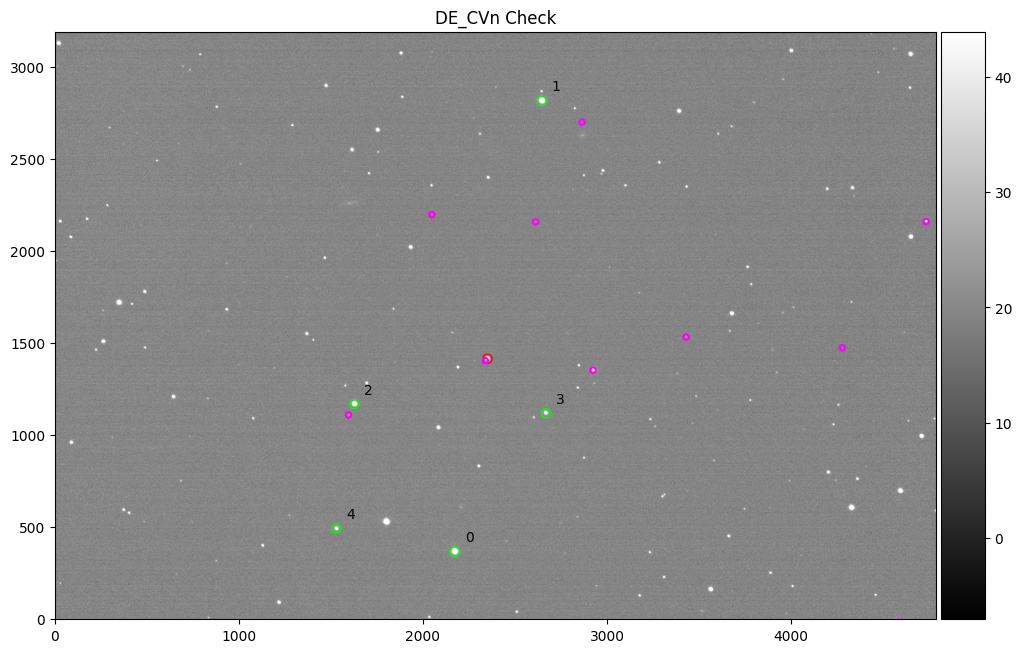

In [21]:
## ---- CHECK REFERENCE IMAGE ----
## Find the RA and Dec of the target and the source image data and search for variable stars in the region. This is done to check that the target and reference stars are correct and to plot the reference image with the target, reference stars, and variable stars marked.
target_ra, target_dec, src, vars, vsx_table = chk.get_target_coordinates(config_data['TARGET_NAME'], config_data['REFERENCE_IMAGE'])
## Convert the reference star pixel coordinates to RA and Dec for plotting and moving between frames
checkstars_radec = chk.stars_to_radec(config_data['STAR_COORDS'], config_data['REFERENCE_IMAGE'])
## Plot the reference image with the target, reference stars, and variable stars marked
chk.plot_reference_image(config_data['TARGET_NAME'], target_ra, target_dec, config_data['REFERENCE_IMAGE'], checkstars_radec, vsx_table, show_ref_stars=True, show_var_stars=True)


Performing photometry for filter: g
Target Name: DE_CVn
Target RA: 201.7198078555489
Target Dec: 45.54499001607914


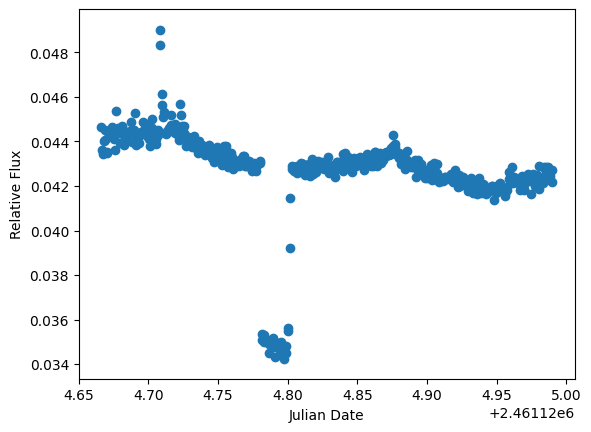

Target Name: DE_CVn
Target RA: 201.719807855102
Target Dec: 45.54499001580723
Target Name: DE_CVn
Target RA: 201.71980785481227
Target Dec: 45.54499001563095
Target Name: DE_CVn
Target RA: 201.71980785307818
Target Dec: 45.544990014575916
Zero point magnitude or error not found in header of  /Users/nhaurber/Data/PCEB/DECVn g 2026-03-25/cwl_DE_CVn_g_15s_2026-03-25T03-53-51_calibrated.fts.fz
Zero point magnitude or error not found in header of  /Users/nhaurber/Data/PCEB/DECVn g 2026-03-25/cwl_DE_CVn_g_15s_2026-03-25T03-53-51_calibrated.fts.fz
Zero point magnitude or error not found in header of  /Users/nhaurber/Data/PCEB/DECVn g 2026-03-25/cwl_DE_CVn_g_15s_2026-03-25T03-53-51_calibrated.fts.fz
Zero point magnitude or error not found in header of  /Users/nhaurber/Data/PCEB/DECVn g 2026-03-25/cwl_DE_CVn_g_15s_2026-03-25T03-53-51_calibrated.fts.fz
Zero point magnitude or error not found in header of  /Users/nhaurber/Data/PCEB/DECVn g 2026-03-25/cwl_DE_CVn_g_15s_2026-03-25T03-53-51_calibrate

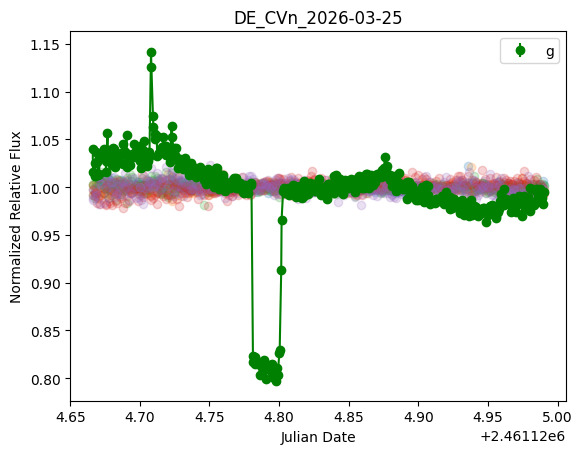

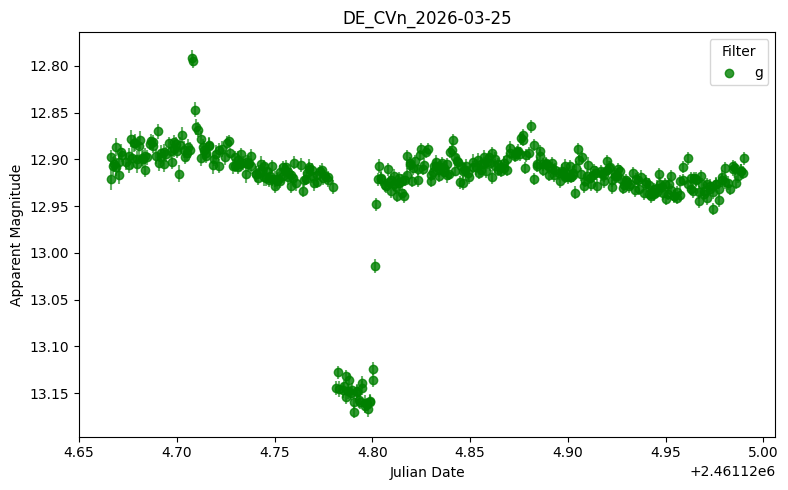

Performing photometry for filter: r
Target Name: DE_CVn
Target RA: 201.7198078527669
Target Dec: 45.54499001438654


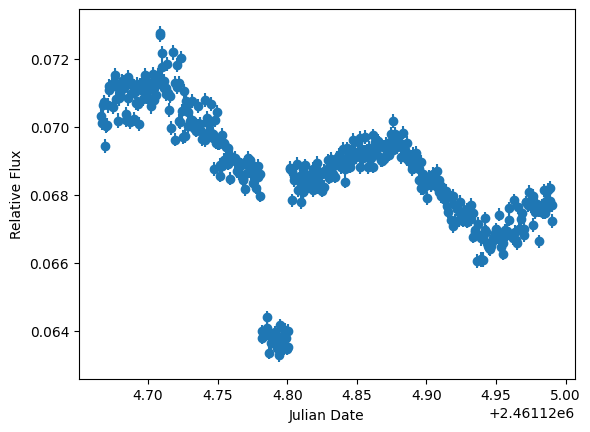

Target Name: DE_CVn
Target RA: 201.71980785163564
Target Dec: 45.54499001369825
Target Name: DE_CVn
Target RA: 201.719807851349
Target Dec: 45.54499001352387
Target Name: DE_CVn
Target RA: 201.71980784963688
Target Dec: 45.54499001248219
Zero point magnitude or error not found in header of  /Users/nhaurber/Data/PCEB/DECVn g 2026-03-25/cwl_DE_CVn_r_15s_2026-03-25T04-42-59_calibrated.fts.fz
Zero point magnitude or error not found in header of  /Users/nhaurber/Data/PCEB/DECVn g 2026-03-25/cwl_DE_CVn_r_15s_2026-03-25T04-42-59_calibrated.fts.fz
Zero point magnitude or error not found in header of  /Users/nhaurber/Data/PCEB/DECVn g 2026-03-25/cwl_DE_CVn_r_15s_2026-03-25T04-42-59_calibrated.fts.fz
Zero point magnitude or error not found in header of  /Users/nhaurber/Data/PCEB/DECVn g 2026-03-25/cwl_DE_CVn_r_15s_2026-03-25T04-42-59_calibrated.fts.fz
Zero point magnitude or error not found in header of  /Users/nhaurber/Data/PCEB/DECVn g 2026-03-25/cwl_DE_CVn_r_15s_2026-03-25T04-42-59_calibrated

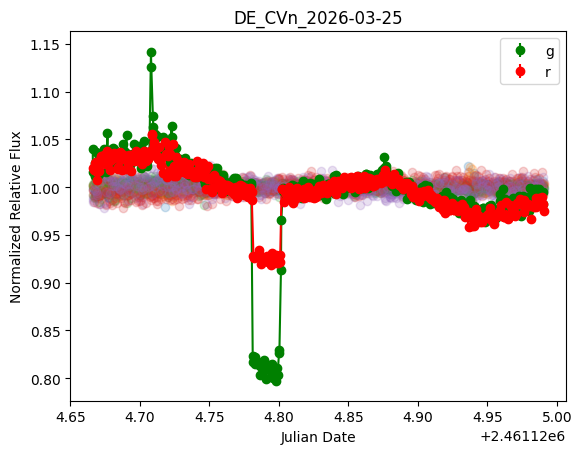

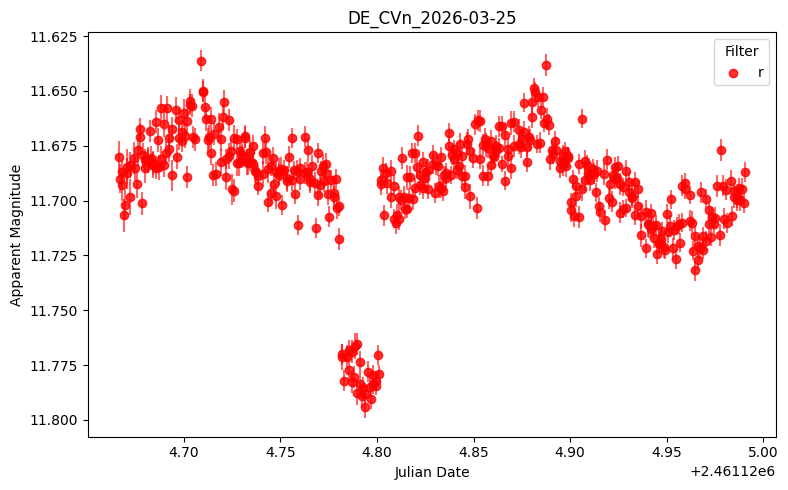

Performing photometry for filter: i
Target Name: DE_CVn
Target RA: 201.71980784932455
Target Dec: 45.544990012292175
  star 2, pos=(2806.1,2812.8), ap_sum=5012.2, bkg_mean=3.6, bkg_sum=5419.3, gain=1.76
Skipping /Users/nhaurber/Data/PCEB/DECVn g 2026-03-25/cwl_DE_CVn_i_15s_2026-03-25T07-53-17_calibrated.fts.fz due to negative source sum on star 2, image should be inspected.


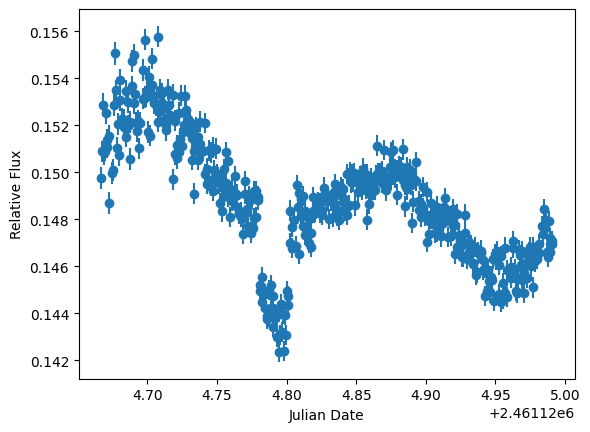

Target Name: DE_CVn
Target RA: 201.71980784819766
Target Dec: 45.544990011606565
  star 2, pos=(2807.5,2812.8), ap_sum=4996.0, bkg_mean=3.6, bkg_sum=5468.9, gain=1.76
Skipping /Users/nhaurber/Data/PCEB/DECVn g 2026-03-25/cwl_DE_CVn_i_15s_2026-03-25T07-53-17_calibrated.fts.fz due to negative source sum on star 2!, image should be inspected.
Target Name: DE_CVn
Target RA: 201.71980784791026
Target Dec: 45.54499001143168
  star 2, pos=(2807.5,2812.8), ap_sum=33713.9, bkg_mean=3.6, bkg_sum=34180.6, gain=1.76
Skipping /Users/nhaurber/Data/PCEB/DECVn g 2026-03-25/cwl_DE_CVn_i_15s_2026-03-25T07-53-17_calibrated.fts.fz due to negative source sum on star 2!, image should be inspected.
Target Name: DE_CVn
Target RA: 201.71980784618256
Target Dec: 45.54499001038053
Zero point magnitude or error not found in header of  /Users/nhaurber/Data/PCEB/DECVn g 2026-03-25/cwl_DE_CVn_i_15s_2026-03-25T04-55-05_calibrated.fts.fz
Zero point magnitude or error not found in header of  /Users/nhaurber/Data/PCEB/D

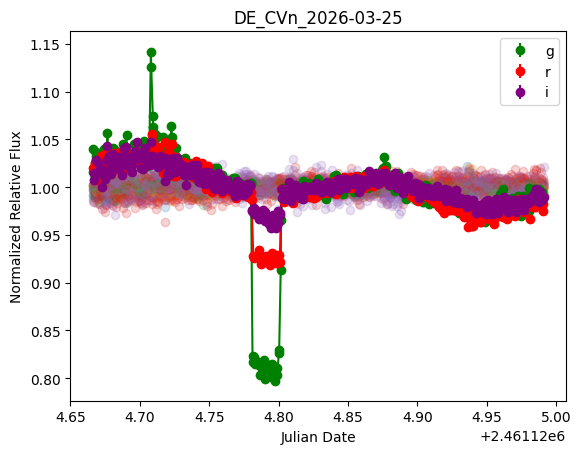

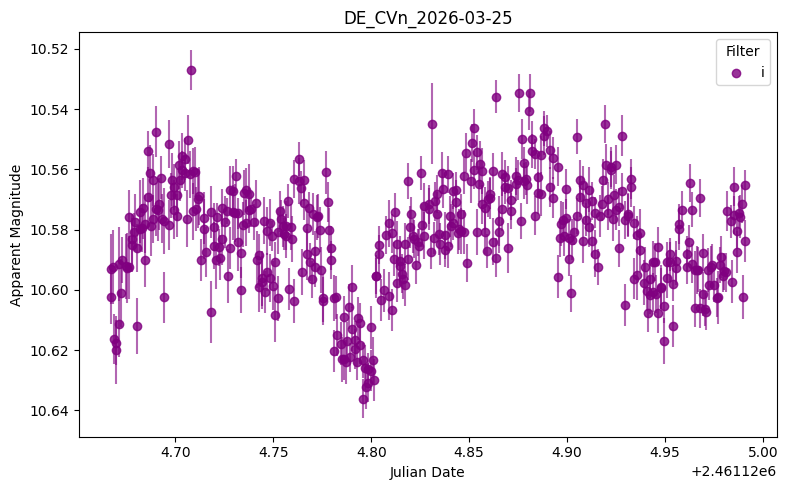

In [22]:
pipe = PhotometryPipeline(
    file_dir=images_location,
    star_list_pix=config_data['STAR_COORDS'],
    ref_image=config_data['REFERENCE_IMAGE'],
    target_name=config_data['TARGET_NAME'],
    rdnoise=RDNOISE,
    aperture_radius=AP_R,
    annulus_inner=AN_I,
    annulus_outer=AN_O,
    gain=GAIN
)

# Loop over the filters and perform the photometry
for filt in FILTERS:
    print('Performing photometry for filter:', filt)
    pipe.perform_var_fwhm_phot(filt, 
                               save_ref_star_coords=False, display_apertures=False, save=True, 
                               plot=True, errorshow=True, title=config_data['TITLE'], non_sidereal=non_sid)
    pipe.calc_ap_ratio(filt, 
                       larger_ap=18, mean=True, median=False, title = config_data['TITLE'])
    
    pipe.find_mags(filt, 
                   save=True, save_ref_star_coords=False, display_apertures=False, title = config_data['TITLE'])
    
    LightCurvePlotter.plot_relative(file_dir=images_location, 
                                    filt=filt, title = config_data['TITLE'], phase=phased, comp_stars=comps, 
                                    phase_zero=config_data['PHASE_ZERO'], period=config_data['PERIOD'], save_path=LK_PATH, errorshow=True)
    
    LightCurvePlotter.plot_absolute(file_dir=images_location, 
                                    title = config_data['TITLE'], filt=filt, phase=phased, 
                                    phase_zero=config_data['PHASE_ZERO'], period=config_data['PERIOD'])